# 01 Site and demand

Umon South ward, Biase LGA, Cross River State: an unelectrified village cluster of about 312 households with a primary school and a health centre. This notebook sets up the two inputs the mini-grid model needs: how much sun there is, hour by hour, and how much electricity the village would use, hour by hour, for one year.

Every choice below was agreed in the project plan; assumptions that are mine rather than from a published source are marked **(assumption)**.

In [1]:
import sys
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
import logging; logging.getLogger("ramp").setLevel(logging.ERROR)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
PROC = ROOT / "data" / "processed"; PROC.mkdir(parents=True, exist_ok=True)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, shapefile
pd.set_option("display.precision", 2)
import data_sources as ds, solar, demand as dm

## 1. The village (RLI / GIZ NESP data, CC BY-SA 4.0)

In [2]:
r = shapefile.Reader(str(ds.rli_cross_river() / "cluster_phases_State_Cross River.shp"))
clusters = pd.DataFrame(r.records(), columns=[f[0] for f in r.fields[1:]])
site = clusters.set_index("ID").loc[ds.SITE["rli_id"]]
site[["LGA", "Ward", "Population", "_Customers", "schools", "health", "dist", "demand",
      "_PV size", "_Battery s", "_Generator", "_RE Share", "phase2"]].rename({
    "_Customers": "customers", "dist": "distance to grid (km?)", "demand": "RLI demand (units?)",
    "_PV size": "RLI design: PV (kWp?)", "_Battery s": "RLI design: battery (kWh?)",
    "_Generator": "RLI design: generator (kW?)", "_RE Share": "RLI design: renewable share (%)",
    "phase2": "RLI plan, phase 2"}).to_frame("value")

,value
LGA,Biase
Ward,UMON SOUTH
Population,1061.21
customers,312
schools,1
health,1
distance to grid (km?),16.65
RLI demand (units?),112
RLI design: PV (kWp?),96
RLI design: battery (kWh?),168


RLI's own design for this cluster is kept as a benchmark for notebook 02. The units are not stated in the shapefile; the question marks stay until they are confirmed from RLI's documentation.

## 2. Sun (PVGIS typical year, SARAH3 2005-2023)

Model in `src/solar.py`: horizontal irradiance used as plane-of-array (near-flat array at 5 N), NOCT cell temperature, -0.4 %/C, 14 % system losses, local time (WAT).

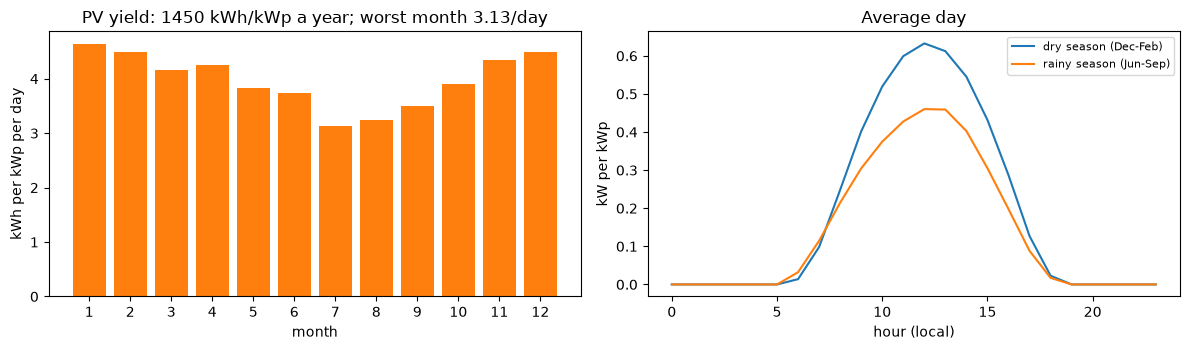

In [3]:
pv = solar.pv_per_kwp()
pv.to_frame().to_parquet(PROC / "pv_per_kwp.parquet")
monthly = pv.resample("ME").sum() / pv.resample("ME").size() * 24
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
axs[0].bar(range(1, 13), monthly.to_numpy(), color="tab:orange")
axs[0].set_xticks(range(1, 13)); axs[0].set_xlabel("month"); axs[0].set_ylabel("kWh per kWp per day")
axs[0].set_title(f"PV yield: {pv.sum():.0f} kWh/kWp a year; worst month {monthly.min():.2f}/day")
for months, label in [([12, 1, 2], "dry season (Dec-Feb)"), ([6, 7, 8, 9], "rainy season (Jun-Sep)")]:
    sel = pv[pv.index.month.isin(months)]
    axs[1].plot(sel.groupby(sel.index.hour).mean(), label=label)
axs[1].set_xlabel("hour (local)"); axs[1].set_ylabel("kW per kWp"); axs[1].legend(fontsize=8); axs[1].set_title("Average day")
fig.tight_layout(); fig.savefig(FIG / "solar_year.png", dpi=150)

## 3. Demand

**Households.** 312 households drawn (with survey weights) from rural households in the World Bank MTF Nigeria 2018 survey, with the appliances they own and the hours they say they use them. Two cases:
- *low*: all rural households (most have no electricity yet, so own few electric appliances);
- *high*: rural households already on the grid.

The survey covers North-West Nigeria only **(assumption that Cross River households use electricity similarly)**. RAMP spreads each appliance's daily hours randomly inside agreed usage windows, a new draw each day, with all units of an appliance switched together so that energy equals count x watts x hours.

**School**: Lighting Global's basic school design (Bwari, FCT), weekdays, closed in August and two weeks at Christmas and Easter **(assumption)**. **Clinic**: Lighting Global's full PHC design (Gudupe) as the low case; the same shape scaled to SEforALL's Type 2 PHC (36 kWh/day) as the high case.

In [4]:
wat = pd.DataFrame([{"appliance": k, "watts": v["w"], "source": {"LG": "Lighting Global (Nigeria)", "RAMP": "RAMP inputs",
                       "NP": "nameplate (assumption)"}[v["src"]], "hours if survey has none": v["hours"]} for k, v in dm.APPLIANCES.items()])
wat

,appliance,watts,source,hours if survey has none
0,LED Light Bulb,10,Lighting Global (Nigeria),NaN
1,Incandescent Light Bulb,60,nameplate (assumption),NaN
2,Compact Fluorescent Light (CFL) Bulb,15,nameplate (assumption),NaN
3,Fluorescent Tube,36,nameplate (assumption),NaN
4,Fan,70,Lighting Global (Nigeria),6.00
5,Regular Color TV,100,Lighting Global (Nigeria),5.00
6,Flat color TV,100,Lighting Global (Nigeria),5.00
7,Black & White TV,100,Lighting Global (Nigeria),5.00
8,VCD/DVD,20,Lighting Global (Nigeria),1.00
9,Radio/CD Players/sound system,36,RAMP inputs,4.40


In [5]:
demand_file = PROC / "demand.parquet"
d = pd.read_parquet(demand_file) if demand_file.exists() else dm.build_all()
d.to_parquet(demand_file)
summary = pd.DataFrame({"kWh/day": d.sum() / 365, "peak kW": d.max(),
                        "busiest hour": d.groupby(d.index.hour).mean().idxmax().astype(str) + ":00"})
summary.loc[["households_low", "households_high"], "kWh/month per household"] = (d[["households_low", "households_high"]].sum() / 12 / dm.N_HOUSEHOLDS).to_numpy()
summary

,kWh/day,peak kW,busiest hour,kWh/month per household
households_low,114.71,14.43,21:00,11.18
households_high,529.74,59.68,22:00,51.64
school,2.43,0.62,9:00,NaN
clinic_low,18.75,1.81,12:00,NaN
clinic_high,36.00,3.49,12:00,NaN


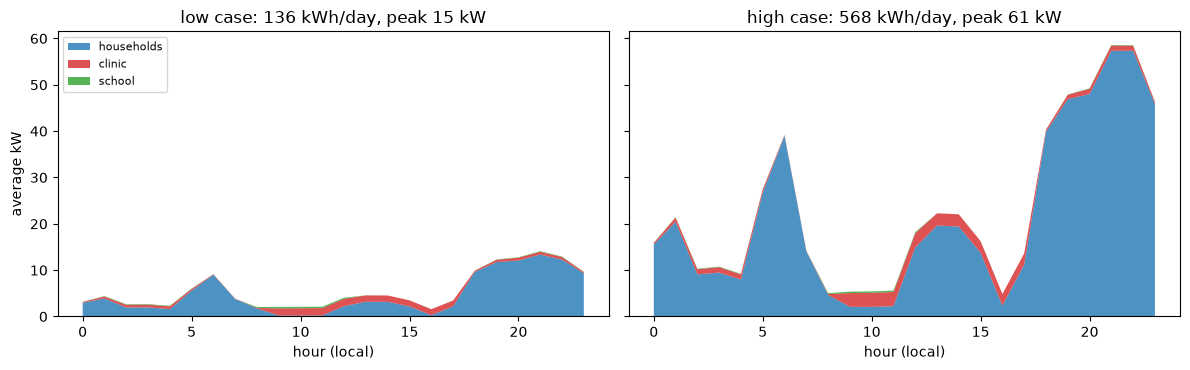

In [6]:
cases = {"low": d.households_low + d.school + d.clinic_low, "high": d.households_high + d.school + d.clinic_high}
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (name, total) in zip(axs, cases.items()):
    hh, cl = d[f"households_{name}"], d[f"clinic_{name}"]
    hour = d.index.hour
    ax.stackplot(range(24), hh.groupby(hour).mean(), cl.groupby(hour).mean(), d.school.groupby(hour).mean(),
                 labels=["households", "clinic", "school"], colors=["tab:blue", "tab:red", "tab:green"], alpha=0.8)
    ax.set_title(f"{name} case: {total.sum() / 365:.0f} kWh/day, peak {total.max():.0f} kW")
    ax.set_xlabel("hour (local)")
axs[0].set_ylabel("average kW"); axs[0].legend(fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "demand_day.png", dpi=150)

## 4. Sanity checks

In [7]:
hh, assets = dm.survey_households()
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    c = pd.read_stata(ds.mtf_nigeria() / "MTF_NG_HH_SEC_C.dta")[["HH_ID", "C_23"]]
rep = hh[hh.on_grid].merge(c, on="HH_ID")
rep_kwh = pd.to_numeric(rep.C_23, errors="coerce").dropna()
model_hh = d.households_high.resample("ME").sum() / dm.N_HOUSEHOLDS
pd.DataFrame({
    "model, high case: kWh/month per household": [model_hh.mean()],
    "survey: rural grid households' reported kWh/month (median)": [rep_kwh.median()],
    "survey: how many households reported it": [len(rep_kwh)],
}).T.rename(columns={0: "value"})

,value
"model, high case: kWh/month per household",51.64
survey: rural grid households' reported kWh/month (median),106.50
survey: how many households reported it,32.00


In [8]:
daily_need = {k: v.sum() / 365 for k, v in cases.items()}
worst = monthly.min()
pd.DataFrame({"kWh/day": daily_need,
              "PV for the average day, no losses (kWp)": {k: v / (pv.sum() / 365) for k, v in daily_need.items()},
              "PV for the worst month (kWp)": {k: v / worst for k, v in daily_need.items()},
              "RLI design PV (kWp?)": site["_PV size"]}).round(0)

,kWh/day,"PV for the average day, no losses (kWp)",PV for the worst month (kWp),RLI design PV (kWp?)
low,136.0,34.0,43.0,96
high,568.0,143.0,182.0,96


## What this shows

- **Sun.** About 1,450 kWh per kWp a year, with a clear rainy-season dip (July-August around 3 kWh/kWp/day against about 4.5 in the dry season). The rainy season is the hard case for a solar-only design.
- **Demand.** The high case is several times the low case: whether new customers behave like households that have had power for years, or like households that are only starting to buy appliances, matters more than any single wattage. The evening peak (21:00-22:00) comes after sunset in both cases, so most household energy must pass through the battery or come from the generator.
- **Clinic and school** are small next to 312 households, but the clinic must never lose power; that constraint, not its energy, will shape the design.
- **Check against the survey.** The high case gives roughly half the monthly consumption that rural grid households report in the survey, but only a few dozen households answered that question, and self-reported kWh is unreliable. A reason to keep both demand cases, not to tune one to that number.
- **Rough size.** A back-of-envelope PV size is about 35-45 kWp for the low case and 145-180 kWp for the high case. RLI's own design for this cluster (96 kWp, units to confirm) falls between the two, and RLI's demand figure (112, units unstated) is close to our low case if it is kWh/day. So the demand is in the right order of magnitude; notebook 02 replaces this back-of-envelope with a proper optimisation.